<a href="https://colab.research.google.com/github/FazelPriyono/Pembelajaran-Mesin-2026/blob/main/TG6_Regresi_244107020033_FazelPriyono.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRAKTIKUM 1
## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Baca Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
data = pd.read_csv('/content/drive/MyDrive/ML_2026/dataset.csv')

## Pemahaman Terhadap Data

In [4]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## Visualisasi Data

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


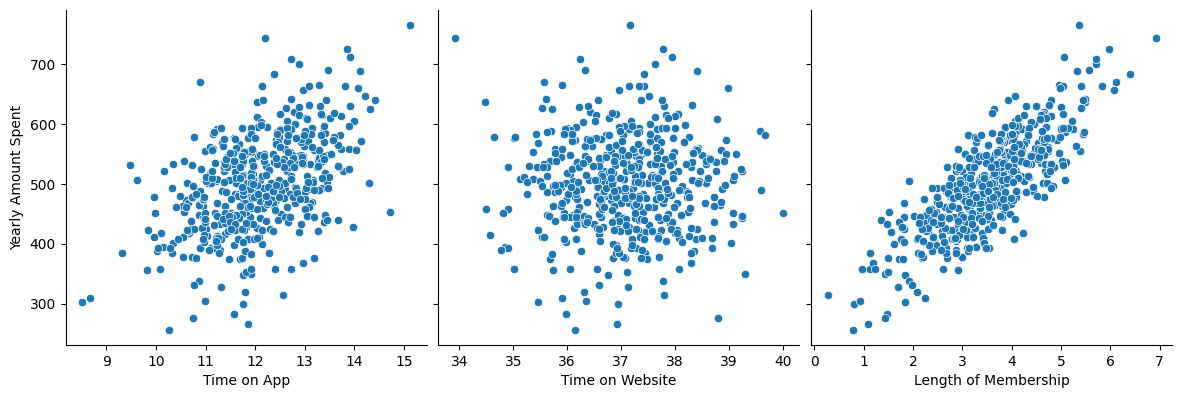

In [5]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

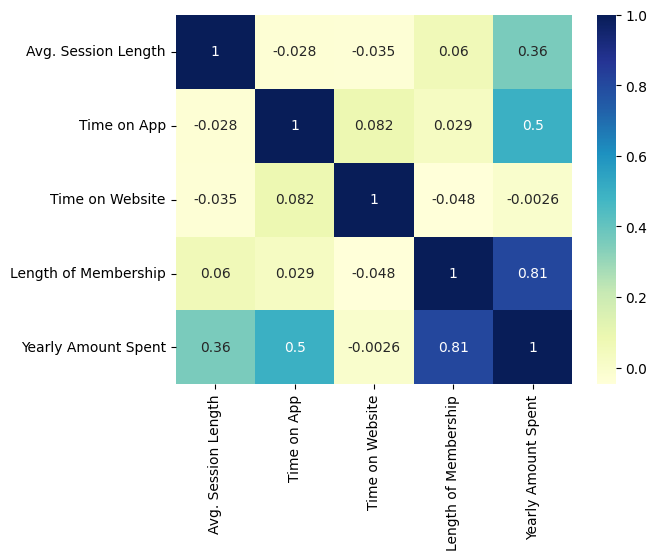

In [6]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

## Regresi Linier

In [7]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [8]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [9]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

In [11]:
# Melihat parameter model (intercept dan slope)
lr.params

,0
const,265.248299
Length of Membership,66.301522


In [12]:
# Menghitung parameter model secara manual
x_mean = X_train.mean()
y_mean = y_train.mean()

# Koefisien regresi (slope)
beta_1 = np.sum((X_train - x_mean) * (y_train - y_mean)) / np.sum((X_train - x_mean) ** 2)

# Intercept
beta_0 = y_mean - beta_1 * x_mean

In [13]:
# Membandingkan parameter hasil manual dengan hasil library (statsmodels)
print("Intercept (manual)  :", beta_0)
print("Intercept (library) :", lr.params['const'])
print()
print("Slope (manual)      :", beta_1)
print("Slope (library)     :", lr.params['Length of Membership'])

Intercept (manual)  : 265.2482985254949
Intercept (library) : 265.2482985254948

Slope (manual)      : 66.30152198546311
Slope (library)     : 66.30152198546311


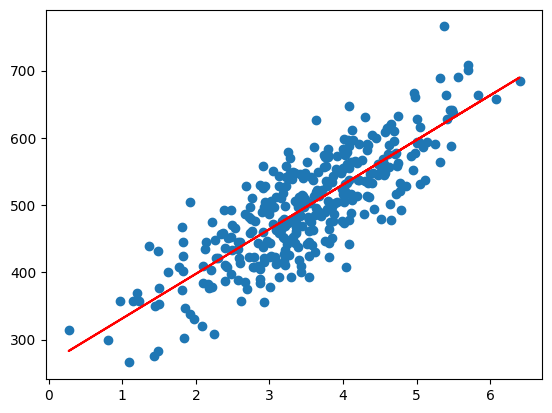

In [10]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

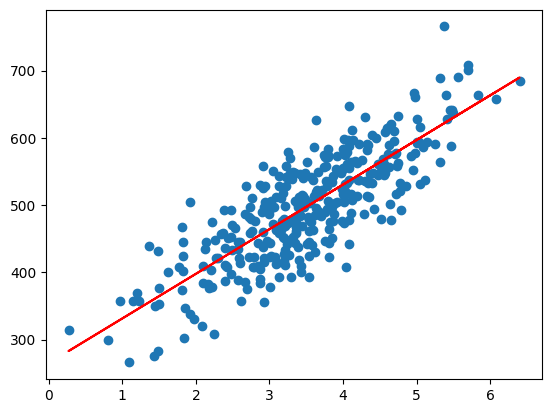

In [14]:
# Visualisasi garis regresi (memakai parameter hasil manual)
plt.scatter(X_train, y_train)
plt.plot(X_train, beta_0 + beta_1*X_train, 'r')
plt.show()

## Analisis Residual

In [15]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

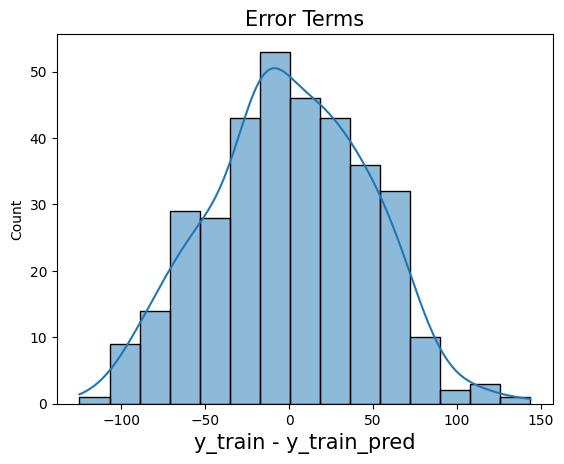

In [16]:
# Histogram residual
fig = plt.figure()
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

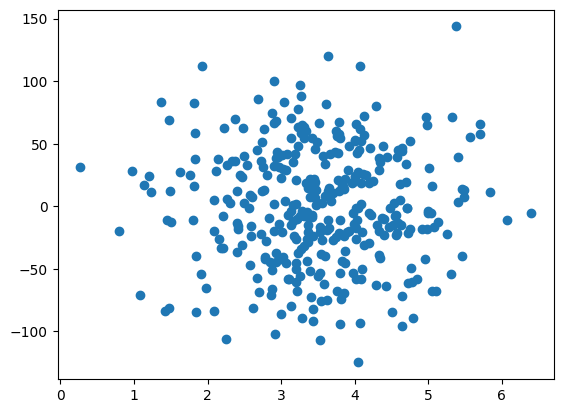

In [17]:
# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [19]:
# Prediksi nilai y dari data latih secara manual (memakai parameter hasil manual)
y_train_pred_manual = beta_0 + beta_1 * X_train

# Menghitung residual secara manual
res_manual = y_train - y_train_pred_manual

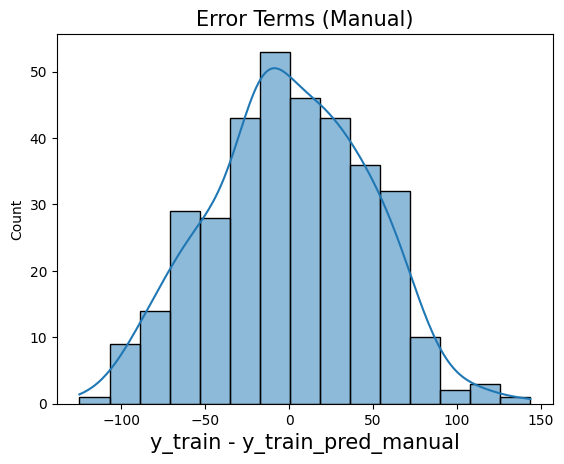

In [20]:
# Histogram residual manual
fig = plt.figure()
sns.histplot(res_manual, bins=15, kde=True)
plt.title('Error Terms (Manual)', fontsize=15)
plt.xlabel('y_train - y_train_pred_manual', fontsize=15)
plt.show()

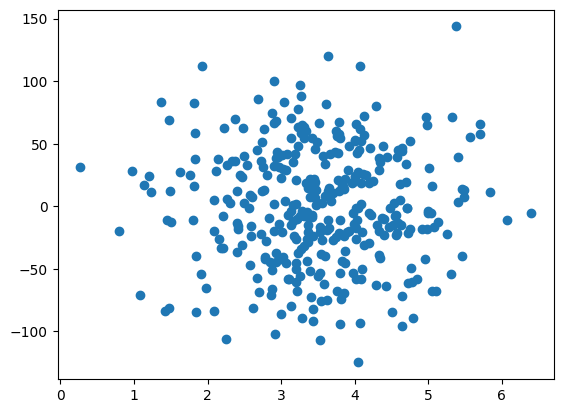

In [21]:
# Scatter plot residual manual
plt.scatter(X_train, res_manual)
plt.show()

In [22]:
# Membandingkan residual hasil manual dan library
print("Rata-rata residual (manual)  :", res_manual.mean())
print("Rata-rata residual (library) :", res.mean())

Rata-rata residual (manual)  : 8.851332365468677e-14
Rata-rata residual (library) : 1.4308300576106247e-13


## Prediksi pada Data Uji dan Evaluasi Model

In [24]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# Prediksi pada data uji secara manual
y_manual_pred = beta_0 + beta_1 * X_test

In [25]:
# Hitung nilai R-squared, MAE, MSE, dan RMSE
r_squared = r2_score(y_test, y_test_pred)

mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

In [26]:
# Hitung nilai R-squared, MAE, MSE, dan RMSE secara manual
RSS = np.sum((y_test - y_manual_pred) ** 2)
TSS = np.sum((y_test - np.mean(y_test)) ** 2)

r2_manual = 1 - (RSS / TSS)
mae_manual = np.mean(np.abs(y_test - y_manual_pred))
mse_manual = np.mean((y_test - y_manual_pred) ** 2)
rmse_manual = np.sqrt(mse_manual)

In [27]:
# Membandingkan hasil manual dan library
hasil = pd.DataFrame({
    'Manual': [r2_manual, mae_manual, mse_manual, rmse_manual],
    'Library': [r_squared, mae, mse, rmse]
}, index=['R-squared', 'MAE', 'MSE', 'RMSE'])

hasil

,Manual,Library
R-squared,0.611949,0.611949
MAE,36.867293,36.867293
MSE,2171.370177,2171.370177
RMSE,46.597963,46.597963


## Visualisasi Hasil

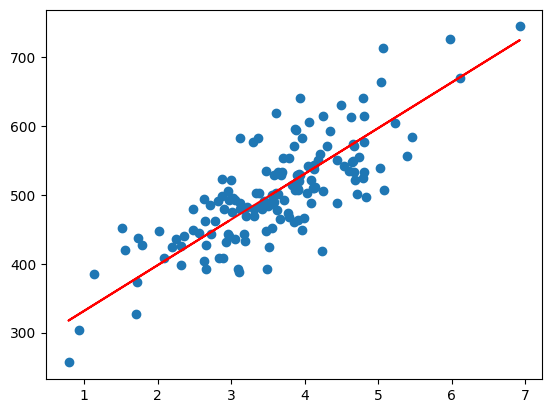

In [28]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

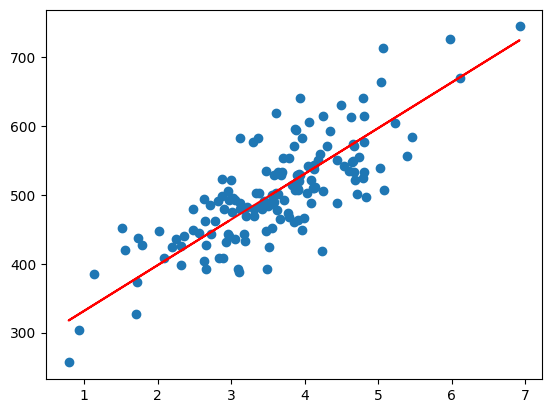

In [29]:
# Visualisasi data uji dan hasil prediksi manual
plt.scatter(X_test, y_test)
plt.plot(X_test, y_manual_pred, 'r')
plt.show()

# PRAKTIKUM 2
##  Import Library

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Mengimpor Dataset

In [31]:
dataset = pd.read_csv('/content/drive/MyDrive/ML_2026/Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

## Feature Scaling

In [32]:
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

- StandardScaler mengubah data supaya rata-ratanya 0 dan sebarannya 1.
- Penskalaan ini diperlukan karena SVR sangat sensitif terhadap skala data. Tingkat posisi (1 sampai 10) dan gaji (puluhan sampai ratusan ribu) selisihnya sangat jauh, sehingga tanpa penskalaan model akan sulit belajar.
- sc_X untuk fitur (tingkat posisi) dan sc_y untuk target (gaji) dibuat terpisah. Keduanya disimpan karena nanti dipakai lagi untuk menskalakan data baru dan mengembalikan hasil prediksi ke skala asli.
- reshape(-1, 1) mengubah data menjadi bentuk 2D (satu kolom), karena fit_transform meminta input 2D.

##  Fitting SVR ke Dataset

In [33]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

## Visualisasi Hasil SVR

/tmp/ipykernel_1504/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


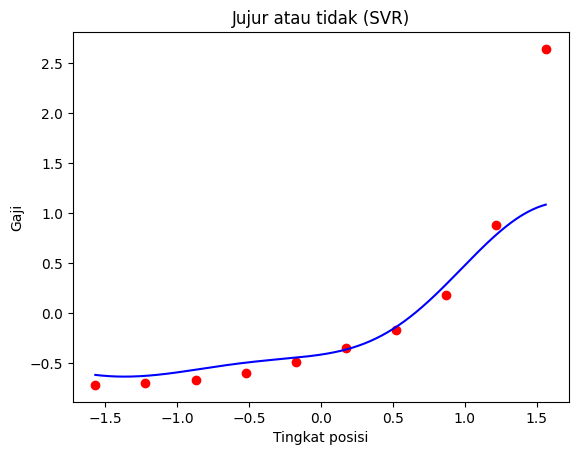

In [34]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

- X_grid membuat deretan titik dengan jarak 0,01 dari nilai terkecil sampai terbesar X, supaya kurva prediksi tampak halus.
- Titik merah adalah data asli (sudah diskalakan), dan garis biru adalah hasil prediksi model SVR.

## Prediksi Hasil

In [35]:
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)

# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)

# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

## Menampilkan Hasil

In [36]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


## Evaluasi Model SVR

In [37]:
y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


# Tugas Praktikum

## **Multiple Linear Regression**

## Import Library

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Baca Data dan Pemahaman Dataset

In [38]:
# baca data
data = pd.read_csv('/content/drive/MyDrive/ML_2026/insurance.csv')

In [40]:
# Tampilkan beberapa baris pertama
display(data.head())

# Informasi dataset
print(data.info())

# Deskripsi statistik
display(data.describe())

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## Visualisasi Data

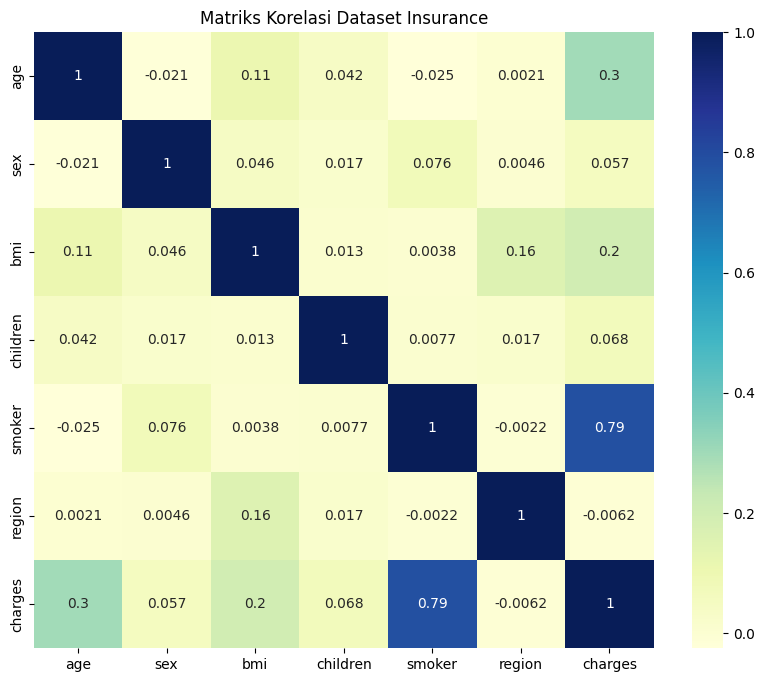

In [41]:
# Melakukan encoding untuk variabel kategorikal sebelum visualisasi korelasi
data_encoded = data.copy()
label_encoders = {}
for col in ['sex', 'smoker', 'region']:
    le = LabelEncoder()
    data_encoded[col] = le.fit_transform(data[col])
    label_encoders[col] = le

# Heatmap korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(data_encoded.corr(), cmap="YlGnBu", annot=True)
plt.title('Matriks Korelasi Dataset Insurance')
plt.show()

## Identifikasi Variabel Bebas dan Target

In [42]:
# Variabel bebas (fitur) dan target (charges)
X = data_encoded.drop(columns=['charges']).values
y = data_encoded['charges'].values

## Pembagian Data Latih dan Data Uji

In [43]:
# Pembagian data dengan proporsi 7:3
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

## Feature Scaling

In [44]:
# Feature Scaling untuk variabel numerik
sc_X = StandardScaler()
sc_y = StandardScaler()

# Lakukan fitting dan transformasi pada data latih, serta transformasi pada data uji
X_train_scaled = sc_X.fit_transform(X_train)
X_test_scaled = sc_X.transform(X_test)

y_train_scaled = sc_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_test_scaled = sc_y.transform(y_test.reshape(-1, 1)).ravel()

## Membuat dan Melatih Model

In [45]:
# Membuat model Multiple Linear Regression
regressor = LinearRegression()
regressor.fit(X_train_scaled, y_train_scaled)

LinearRegression()

## Prediksi pada Data Uji

In [46]:
# Prediksi pada data uji
y_pred_scaled = regressor.predict(X_test_scaled)

# Kembalikan hasil prediksi ke skala aslinya
y_pred = sc_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

## Evaluasi Model

In [47]:
# Evaluasi Model
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Hasil Evaluasi Model Multiple Linear Regression:")
print(f"R-squared : {r2:.4f}")
print(f"MAE       : {mae:.4f}")
print(f"MSE       : {mse:.4f}")
print(f"RMSE      : {rmse:.4f}")

Hasil Evaluasi Model Multiple Linear Regression:
R-squared : 0.7783
MAE       : 3935.5643
MSE       : 32191230.3657
RMSE      : 5673.7316


## Analisis Hasil

### **Analisis Hasil, Evaluasi, dan Kesimpulan**

Berdasarkan hasil pemodelan menggunakan *Multiple Linear Regression*, faktor kebiasaan merokok (**smoker**) terbukti memiliki pengaruh paling dominan terhadap tingginya biaya medis (**charges**) dengan korelasi mencapai $0.79$, disusul oleh faktor usia dan indeks massa tubuh (BMI). Dari hasil pengujian model pada data uji, diperoleh nilai **R-squared ($R^2$) sebesar $0.7783$**, yang berarti bahwa seluruh variabel bebas dalam model ini mampu menjelaskan $77.83\%$ variasi biaya medis pasien, sementara $22.17\%$ sisanya dipengaruhi faktor lain di luar dataset. Selisih rata-rata antara hasil prediksi model dengan biaya medis riil ditunjukkan oleh nilai **MAE sebesar $3935.5643$** dan **RMSE sebesar $5673.7316$** (dalam satuan USD).

Kesimpulan dari studi kasus ini menunjukkan bahwa model Multi Linear Regression ini sudah cukup baik dan layak digunakan untuk mengestimasi pengeluaran biaya medis pasien. Faktor gaya hidup, terutama kebiasaan merokok, jauh lebih memicu lonjakan biaya kesehatan dibanding karakteristik fisik lainnya. **Kelebihan utama** dari metode ini adalah proses komputasinya yang sangat cepat serta hasilnya yang mudah dibaca dan diinterpretasikan secara langsung. Namun, **kelemahan utamanya** terletak pada ketergantungan asumsi hubungan linier yang kaku, sehingga model ini cenderung kurang akurat jika data di lapangan memiliki pola yang kompleks atau mengandung banyak (*outliers*) ekstrem.